In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import ndimage as ndi
import cv2 as cv
import os

DATA_DIR = Path("Database_134_Angiograms")
IMG_ID = 1          # kullanılacak görüntü

In [118]:
def histogram_plot(image):
    histogram, bin_edges = np.histogram(image, bins=256, range=(0, 255))
    plt.figure()
    plt.title("Histogram")
    plt.xlabel("Pixel Value")
    plt.ylabel("Frequency")
    plt.plot(bin_edges[:-1], histogram, color='blue')
    plt.show()

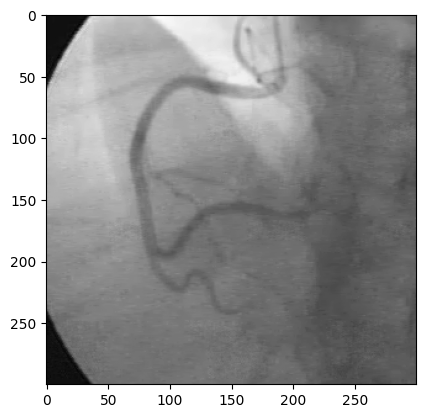

In [11]:
image= cv.imread(os.path.join(DATA_DIR, f"{IMG_ID}.pgm"), cv.IMREAD_GRAYSCALE)

plt.imshow(image, cmap='gray')
plt.show()


## 1. SMOOTHING


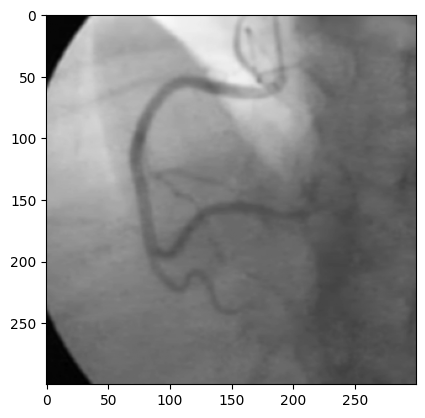

In [12]:
gaussian_filtered = ndi.gaussian_filter(image, sigma=1)
plt.imshow(gaussian_filtered, cmap='gray')

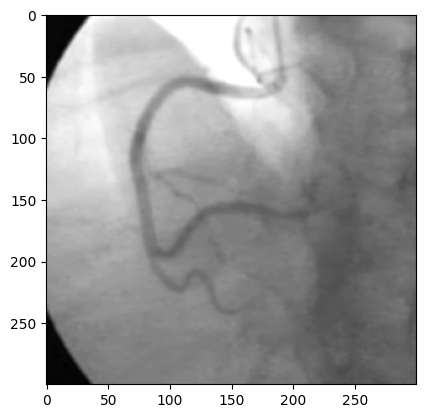

In [15]:
contrast_image = cv.convertScaleAbs(gaussian_filtered, alpha=1.5, beta=0)
plt.imshow(contrast_image, cmap='gray')
plt.show()

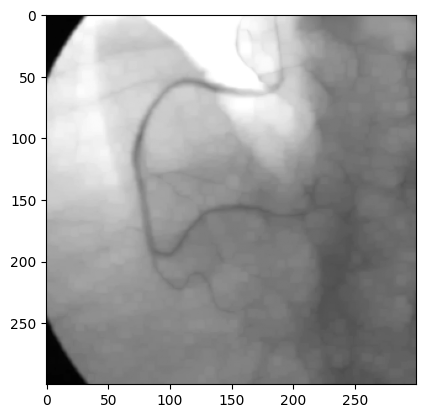

In [135]:
max_filtered = ndi.maximum_filter(contrast_image, size=5)
plt.imshow(max_filtered, cmap='gray')

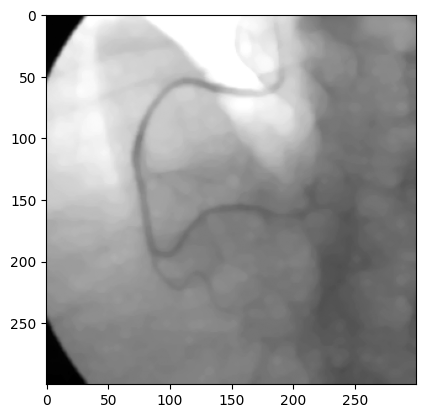

In [136]:
median_filtered = cv.medianBlur(max_filtered, 5)
plt.imshow(median_filtered, cmap='gray')
plt.show()

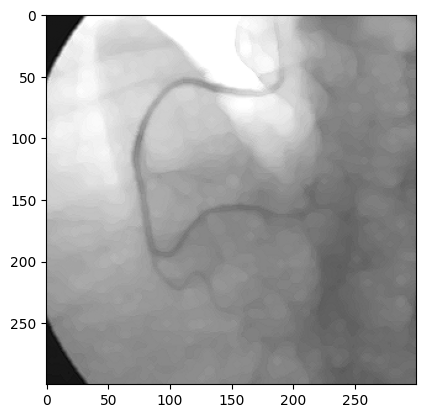

In [141]:
laplacian_filtered = cv.Laplacian(median_filtered, cv.CV_64F)
alpha = 0.7  # Artırdıkça keskinlik artar; gürültü de belirginleşebilir
sharpened = np.clip(
    median_filtered.astype(np.float64) - alpha * laplacian_filtered,
    0, 255
).astype(np.uint8)
plt.imshow(sharpened, cmap='gray')

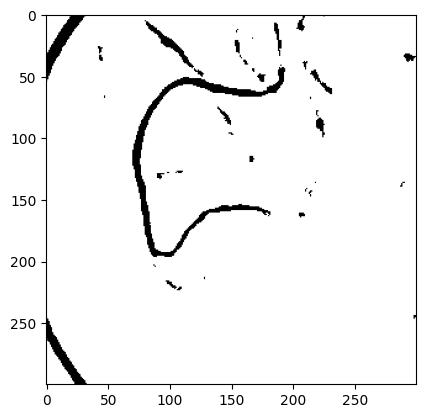

In [217]:
adaptive_threshold = cv.adaptiveThreshold(median_filtered, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY_INV, 31, 8)
negative_image = 255 - adaptive_threshold
plt.imshow(negative_image, cmap='gray')
plt.show()

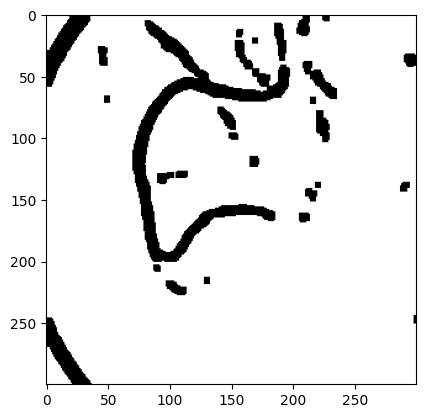

In [227]:
erosioned_image = cv.erode(negative_image, kernel=np.ones((3, 3), np.uint8), iterations=2)
dilated_image = cv.dilate(erosioned_image, kernel=np.ones((2, 2), np.uint8), iterations=2)
erosioned_image = cv.erode(dilated_image, kernel=np.ones((2, 2), np.uint8), iterations=2)
plt.imshow(erosioned_image, cmap='gray')
plt.show()

## Belong to old trials

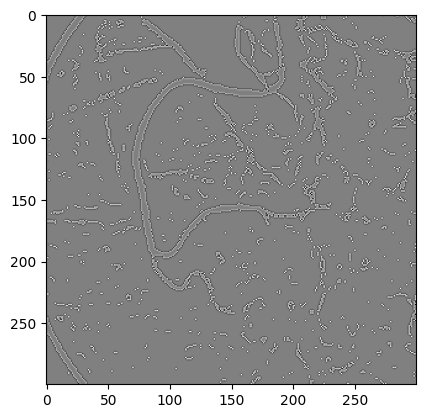

In [82]:
explonation = cv.Laplacian(negative_image, cv.CV_64F)
plt.imshow(explonation, cmap='gray')

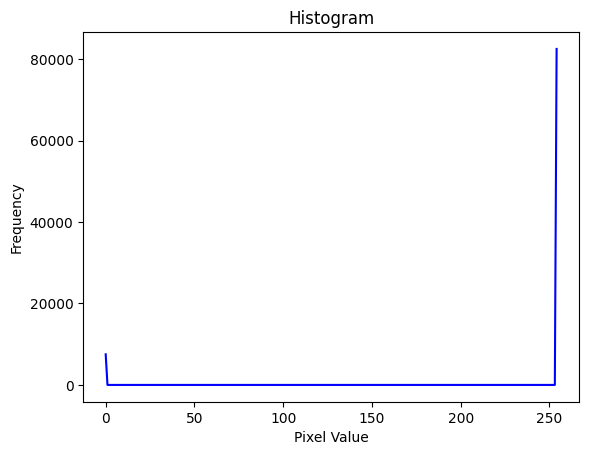

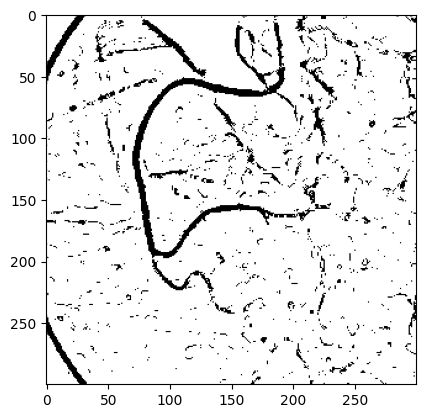

In [87]:
image_norm = cv.normalize(
    negative_image.astype(np.float32),
    None,
    alpha=0,
    beta=255,
    norm_type=cv.NORM_MINMAX
).astype(np.uint8)

plt.imshow(image_norm, cmap="gray", vmin=0, vmax=255)
plt.show()

In [88]:
np.min(image_norm), np.max(image_norm)

(0, 255)

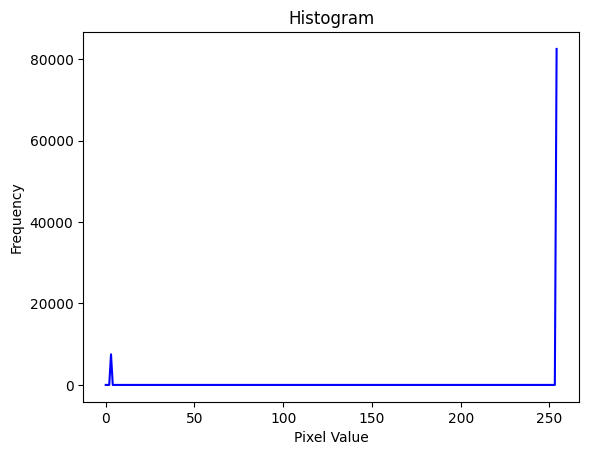

In [93]:
histogram, bin_edges = np.histogram(clahe_image, bins=256, range=(0, 255))
plt.figure()
plt.title("Histogram")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.plot(bin_edges[:-1], histogram, color='blue')
plt.show()

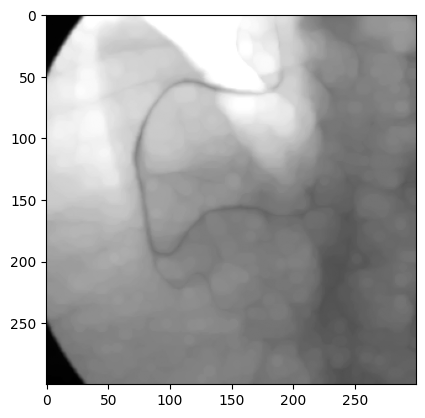

In [ ]:
dilated_image = cv.dilate(median_filtered, kernel=np.ones((3, 3), np.uint8), iterations=1)
plt.imshow(dilated_image, cmap='gray')
plt.show()

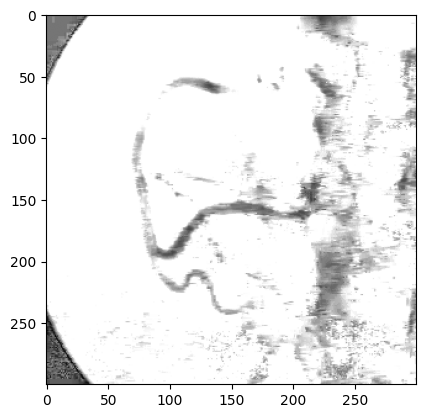

In [52]:
brightened_image = np.clip(
    clahe_image.astype(np.int16) + brightness,
    0,
    255
).astype(np.uint8)
plt.imshow(brightened_image, cmap='gray')

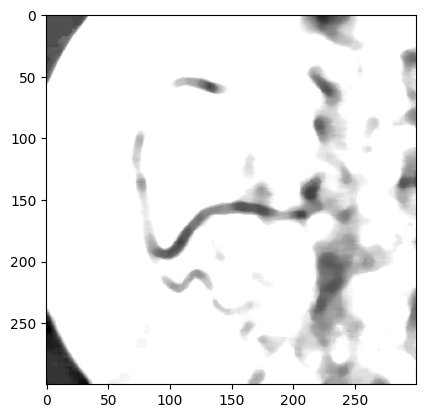

In [57]:
median_filtered = cv.medianBlur(brightened_image, 9)
plt.imshow(median_filtered, cmap='gray')

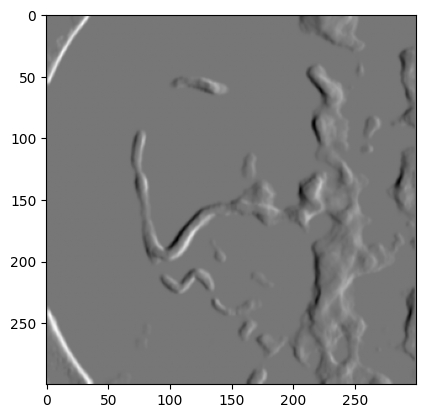

In [60]:
sobel_x = cv.Sobel(median_filtered, cv.CV_64F, 1, 0, ksize=5)
sobel_y = cv.Sobel(median_filtered, cv.CV_64F, 0, 1, ksize=5)
plt.imshow(sobel_x, cmap='gray')

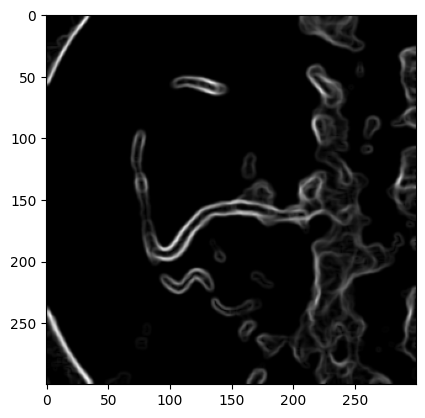

In [61]:
sobeled_image = np.sqrt(sobel_x**2 + sobel_y**2)
plt.imshow(sobeled_image, cmap='gray')

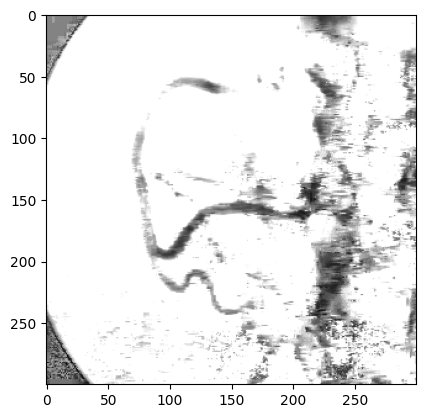

In [54]:
clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_image = clahe.apply(brightened_image)
plt.imshow(clahe_image, cmap='gray')